# Tutorial 03: Model Evaluation and Residual Diagnostics

Mathematics for Machine Learning

Thomas Manke  
2026-10-14

## Setup

### Teams, Tasks, and Environments

Duration: ~15 minutes

1.  Form teams of 2 students + corresponding task assignment (Task A or
    Task B).
2.  Start JupyterLab on your laptop,
    <a href="https://colab.research.google.com/" target="_blank"
    rel="noopener">Google Colab</a>, or local environment.
3.  Run the environment check cell below to confirm Python 3, NumPy,
    Scikit-Learn, and Matplotlib are functioning, and load the
    real-world **UCI Diabetes Dataset** ($n = 442$ patients):

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression

# Load real-world UCI Diabetes Dataset
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

print("Environment check passed.")
print(f"Loaded UCI Diabetes Dataset: {df.shape[0]} patients, {df.shape[1]-1} features.")
print("First 5 patient observations:")
df.head()

Environment check passed.
Loaded UCI Diabetes Dataset: 442 patients, 10 features.
First 5 patient observations:

------------------------------------------------------------------------

## Task A: Predictive Error Metrics & Goodness of Fit

In Task A, you will analyze real clinical measurements from $n = 442$
diabetes patients to evaluate model accuracy using physical error
metrics ($\text{MAE}$, $\text{RMSE}$) and goodness of fit ($R^2$,
$R^2_{\text{adj}}$).

### Task A.1: Data Inspection & Model Setup

1.  Inspect the target variable `target` (quantitative disease
    progression 1 year after baseline) and feature `bmi` (Body Mass
    Index).
2.  Set up the feature vector $X$ containing `bmi` and `bp` (average
    blood pressure) and target vector $y$.

In [2]:
# Extract features (BMI, Blood Pressure) and target (Disease Progression)
X_features = df[['bmi', 'bp']]
y = df['target'].values
n = len(y)
p = X_features.shape[1] + 1  # 2 features + 1 bias column = 3 parameters

print(f"Sample size n = {n}, Number of parameters p = {p}")

Sample size n = 442, Number of parameters p = 3

### Task A.2: Model Fitting & Prediction

1.  Instantiate `LinearRegression(fit_intercept=True)` from
    `scikit-learn` and fit the model on `X_features` and `y`.
2.  Compute model predictions $\hat{y}$ and residual errors
    $e = y - \hat{y}$.

In [3]:
# Fit linear model
model = LinearRegression(fit_intercept=True)
model.fit(X_features, y)

# Predictions and residuals
y_hat = model.predict(X_features)
residuals = y - y_hat

print(f"Intercept (theta_0): {model.intercept_:.2f}")
print(f"Slope BMI (theta_1): {model.coef_[0]:.2f}")
print(f"Slope BP  (theta_2): {model.coef_[1]:.2f}")

Intercept (theta_0): 152.13
Slope BMI (theta_1): 790.40
Slope BP  (theta_2): 402.21

### Task A.3: Metric Computation (MAE, RMSE, $R^2$, Adjusted $R^2$)

1.  Compute Mean Absolute Error ($\text{MAE}$):
    $$\text{MAE} = \frac{1}{n}\sum_{i=1}^n |y_i - \hat{y}_i|$$
2.  Compute Root Mean Squared Error ($\text{RMSE}$):
    $$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^n (y_i - \hat{y}_i)^2}$$
3.  Compute Coefficient of Determination ($R^2$) and Adjusted $R^2$
    ($R^2_{\text{adj}}$):
    $$R^2 = 1 - \frac{\text{SSE}}{\text{SST}}, \quad R^2_{\text{adj}} = 1 - (1 - R^2)\frac{n - 1}{n - p}$$

In [4]:
mae = np.mean(np.abs(residuals))
sse = np.sum(residuals**2)
sst = np.sum((y - np.mean(y))**2)
rmse = np.sqrt(sse / n)

r2 = 1 - (sse / sst)
r2_adj = 1 - ((sse / (n - p)) / (sst / (n - 1)))

print(f"Mean Absolute Error (MAE) : {mae:.2f}")
print(f"Root Mean Sq Error  (RMSE): {rmse:.2f}")
print(f"R-squared           (R^2) : {r2:.4f}")
print(f"Adjusted R-squared  (R^2_adj): {r2_adj:.4f}")

Mean Absolute Error (MAE) : 49.18
Root Mean Sq Error  (RMSE): 59.85
R-squared           (R^2) : 0.3960
Adjusted R-squared  (R^2_adj): 0.3932

------------------------------------------------------------------------

## Task B: Residual Diagnostics & Outlier Remediation

In Task B, you will evaluate whether classical OLS assumptions hold for
the diabetes regression model by building a 4-panel residual diagnostic
suite and identifying influential outliers using Cook’s Distance
($D_i$).

### Task B.1: 4-Panel Residual Diagnostic Suite

1.  Construct a 4-panel subplot in Matplotlib:
    -   **Panel 1 (Residuals vs. Fitted):** Check linearity.
    -   **Panel 2 (Normal Q-Q Plot):** Check Gaussian error normality.
    -   **Panel 3 (Scale-Location):** Check homoscedasticity
        ($\sqrt{|\text{Standardized Residuals}|}$).
    -   **Panel 4 (Residual Distribution):** Check residual histogram
        against normal PDF curve.

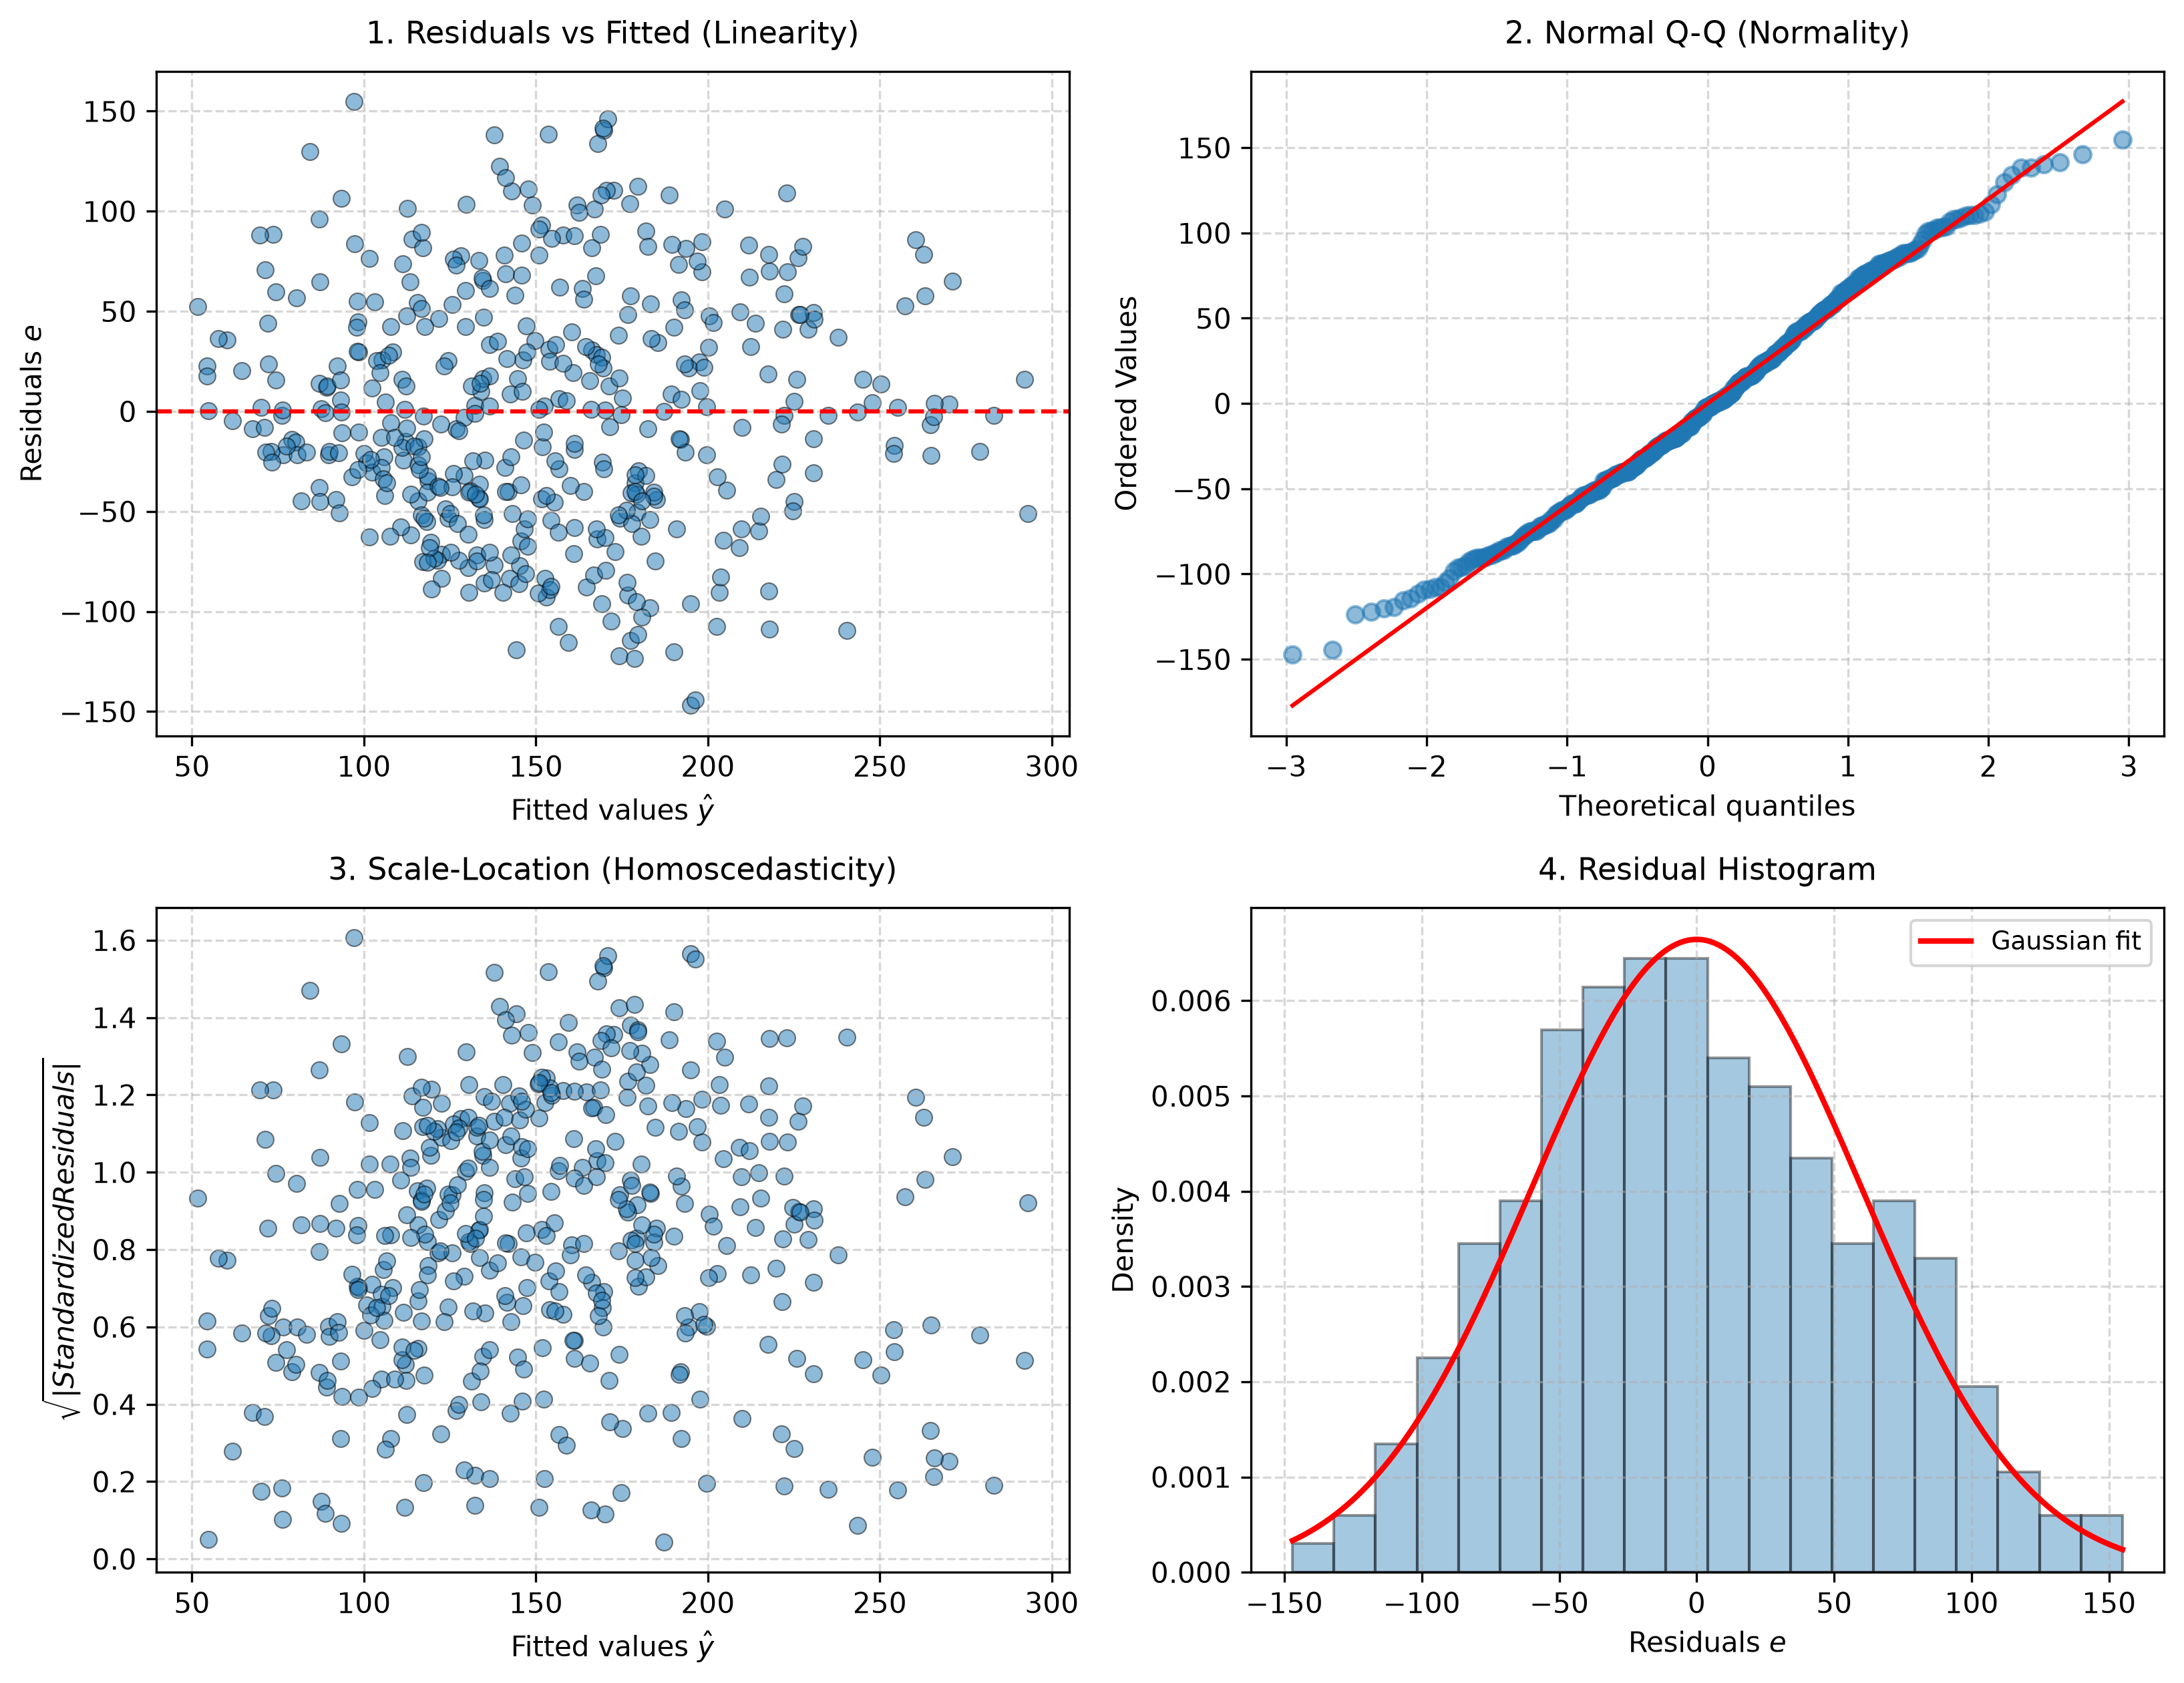

In [5]:
sigma_hat = np.sqrt(sse / (n - p))
std_residuals = residuals / sigma_hat

fig, axes = plt.subplots(2, 2, figsize=(11, 8.5), dpi=300)

# Panel 1: Residuals vs Fitted
axes[0, 0].scatter(y_hat, residuals, color='#1f77b4', alpha=0.5, edgecolors='k', linewidth=0.5)
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=1.5)
axes[0, 0].set_xlabel('Fitted values $\hat{y}$', fontsize=10)
axes[0, 0].set_ylabel('Residuals $e$', fontsize=10)
axes[0, 0].set_title('1. Residuals vs Fitted (Linearity)', fontsize=11, pad=10)
axes[0, 0].grid(True, linestyle='--', alpha=0.5)

# Panel 2: Normal Q-Q
stats.probplot(residuals, dist="norm", plot=axes[0, 1])
axes[0, 1].get_lines()[0].set_color('#1f77b4')
axes[0, 1].get_lines()[0].set_alpha(0.5)
axes[0, 1].get_lines()[1].set_color('red')
axes[0, 1].get_lines()[1].set_linewidth(1.5)
axes[0, 1].set_title('2. Normal Q-Q (Normality)', fontsize=11, pad=10)
axes[0, 1].grid(True, linestyle='--', alpha=0.5)

# Panel 3: Scale-Location
axes[1, 0].scatter(y_hat, np.sqrt(np.abs(std_residuals)), color='#1f77b4', alpha=0.5, edgecolors='k', linewidth=0.5)
axes[1, 0].set_xlabel('Fitted values $\hat{y}$', fontsize=10)
axes[1, 0].set_ylabel('$\sqrt{|Standardized Residuals|}$', fontsize=10)
axes[1, 0].set_title('3. Scale-Location (Homoscedasticity)', fontsize=11, pad=10)
axes[1, 0].grid(True, linestyle='--', alpha=0.5)

# Panel 4: Histogram
axes[1, 1].hist(residuals, bins=20, density=True, color='#1f77b4', alpha=0.4, edgecolor='k')
x_grid = np.linspace(np.min(residuals), np.max(residuals), 200)
pdf_grid = stats.norm.pdf(x_grid, loc=0, scale=sigma_hat)
axes[1, 1].plot(x_grid, pdf_grid, color='red', linewidth=2, label='Gaussian fit')
axes[1, 1].set_xlabel('Residuals $e$', fontsize=10)
axes[1, 1].set_ylabel('Density', fontsize=10)
axes[1, 1].set_title('4. Residual Histogram', fontsize=11, pad=10)
axes[1, 1].grid(True, linestyle='--', alpha=0.5)
axes[1, 1].legend(loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

### Task B.2: Computing Leverage ($h_{ii}$) & Cook’s Distance ($D_i$)

1.  Construct design matrix
    $X_{\text{full}} = [1, \text{bmi}, \text{bp}]$.
2.  Compute Hat matrix
    $H = X_{\text{full}}(X_{\text{full}}^T X_{\text{full}})^{-1} X_{\text{full}}^T$
    and extract leverage diagonal values $h_{ii}$.
3.  Compute Cook’s Distance:
    $$D_i = \frac{e_i^2}{p \cdot s^2} \cdot \frac{h_{ii}}{(1 - h_{ii})^2}$$
4.  Plot Cook’s Distance values across patient indices with a cutoff
    threshold line at $D_i = 4/n$.

Threshold cutoff (4/n) = 0.0090
Number of influential outliers flagged: 22 out of 442 patients.

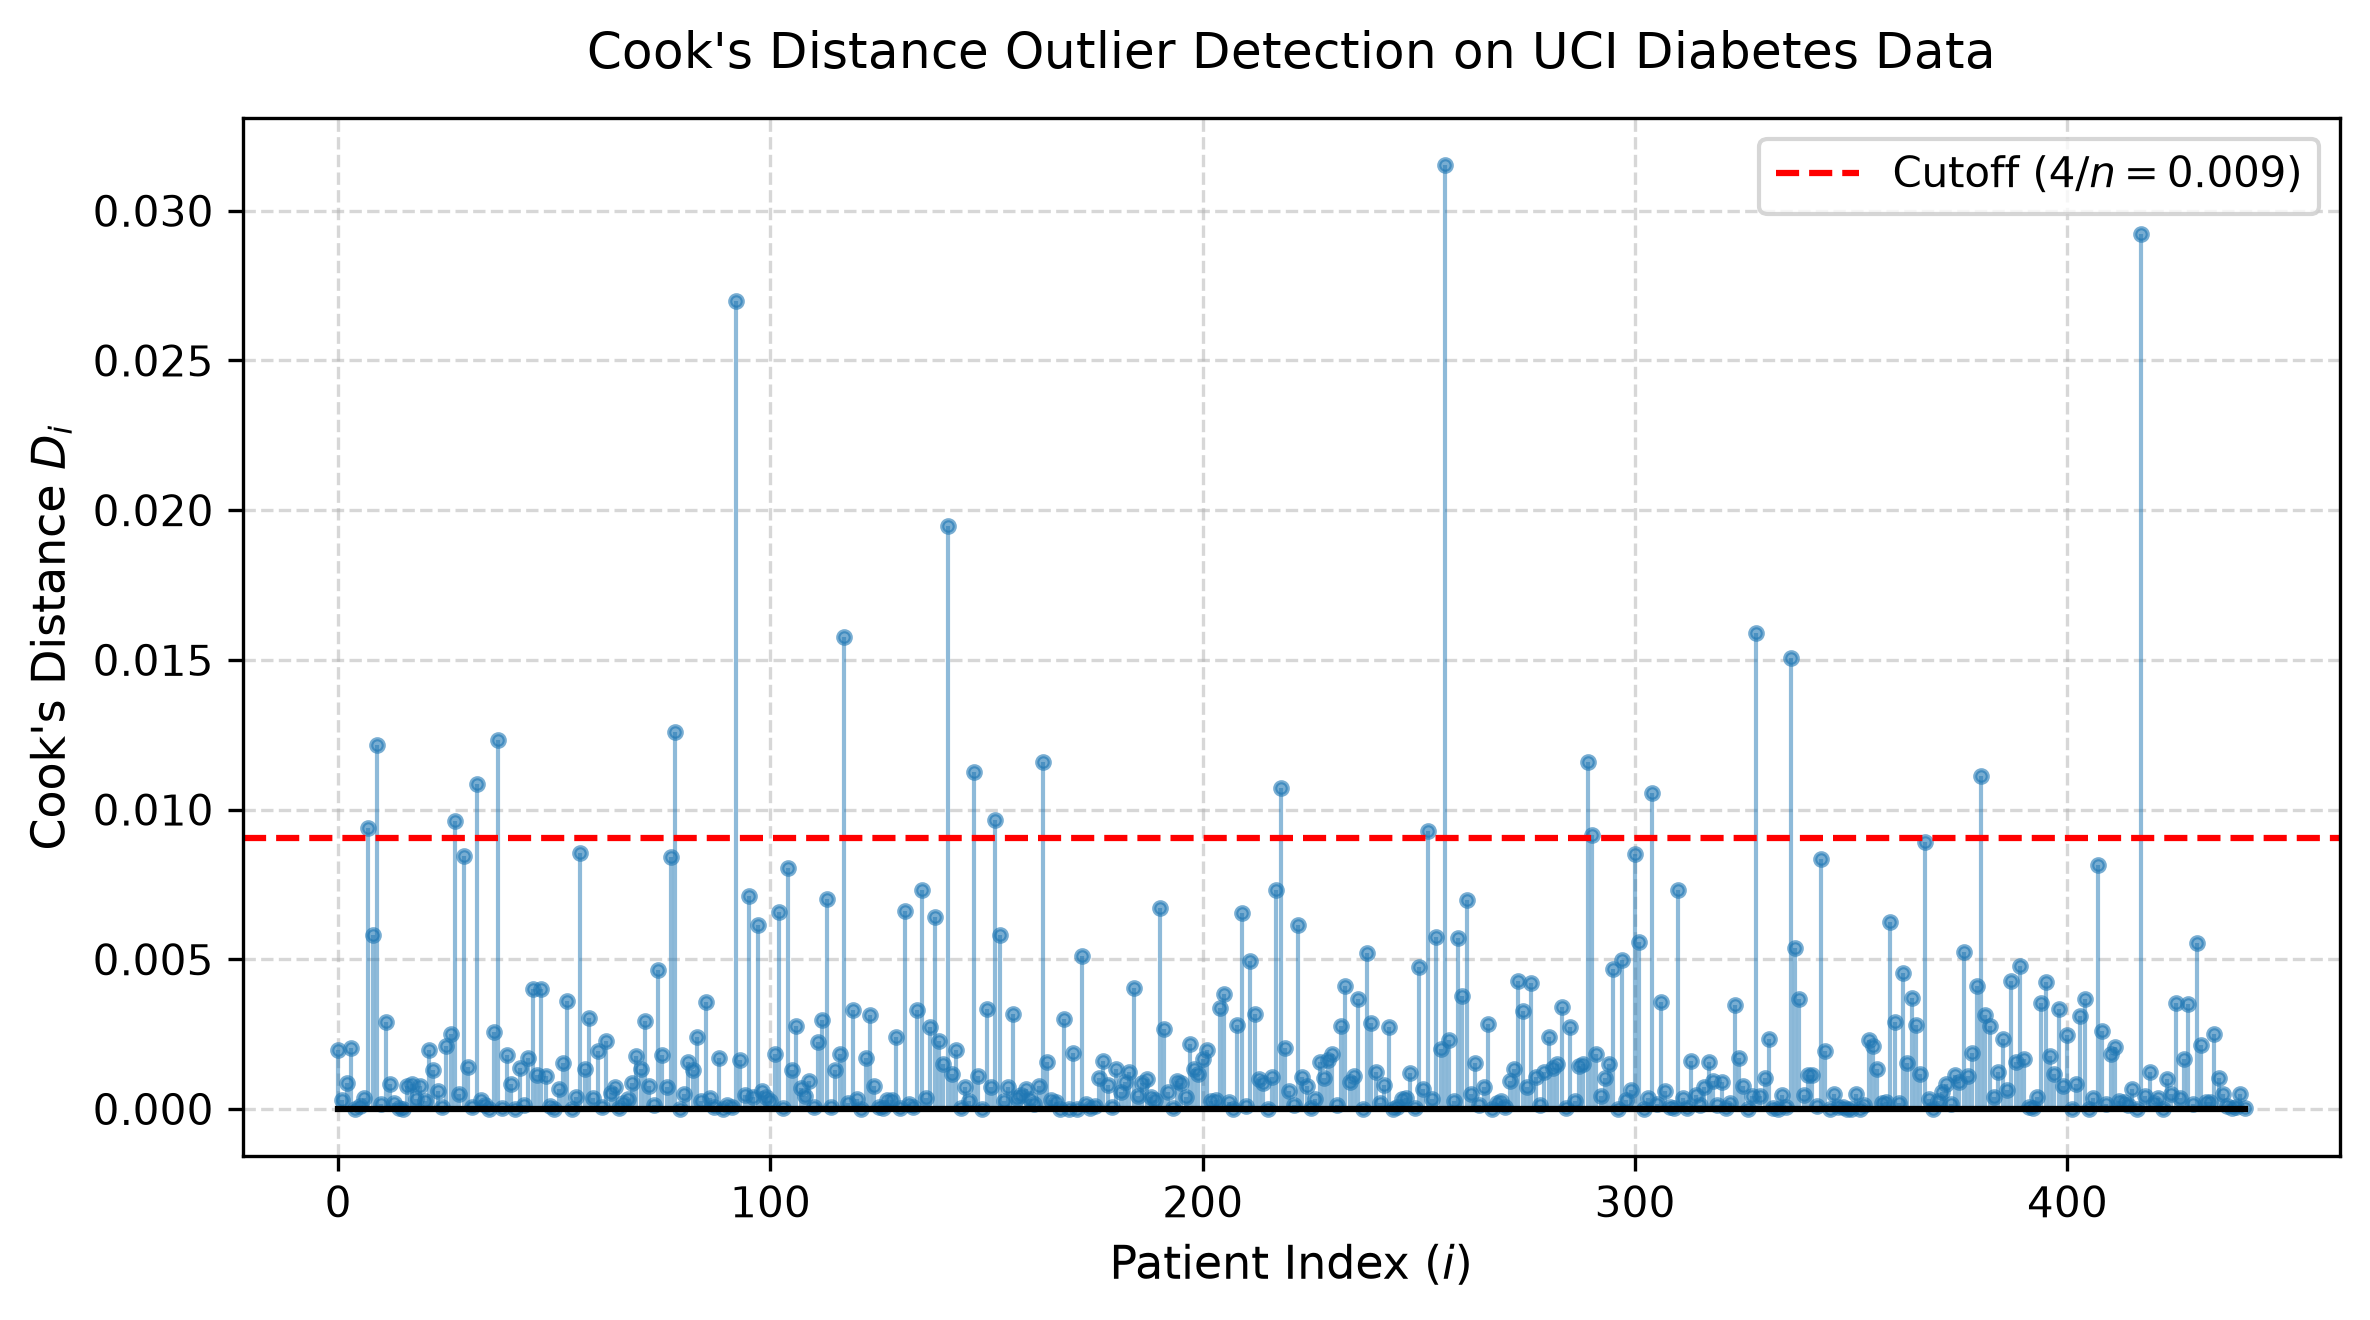

In [6]:
# Design matrix with intercept column
X_full = np.column_stack([np.ones(n), X_features.values])

# Hat matrix and leverage h_ii
H = X_full @ np.linalg.inv(X_full.T @ X_full) @ X_full.T
leverage = np.diag(H)

# Cook's Distance D_i
s_sq = sse / (n - p)
cooks_d = (residuals**2 / (p * s_sq)) * (leverage / (1 - leverage)**2)

# Threshold 4/n
cutoff = 4 / n
influential_mask = cooks_d > cutoff
num_influential = np.sum(influential_mask)

print(f"Threshold cutoff (4/n) = {cutoff:.4f}")
print(f"Number of influential outliers flagged: {num_influential} out of {n} patients.")

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=300)
markerline, stemlines, baseline = ax.stem(range(n), cooks_d, linefmt='-', markerfmt='o', basefmt='k-')
plt.setp(markerline, color='#1f77b4', markersize=3, alpha=0.6)
plt.setp(stemlines, color='#1f77b4', alpha=0.5, linewidth=1.0)

ax.axhline(cutoff, color='red', linestyle='--', linewidth=1.5, label=f'Cutoff ($4/n = {cutoff:.3f}$)')
ax.set_xlabel('Patient Index ($i$)', fontsize=11)
ax.set_ylabel("Cook's Distance $D_i$", fontsize=11)
ax.set_title("Cook's Distance Outlier Detection on UCI Diabetes Data", fontsize=12, pad=12)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()

### Task B.3: Refitting Model Without Influential Outliers

1.  Filter out the flagged influential outliers ($D_i \le 4/n$).
2.  Refit the linear model on the clean patient subset and compare the
    new $R^2_{\text{adj}}$ with the original model.

In [7]:
# Filter clean subset
X_clean = X_features[~influential_mask]
y_clean = y[~influential_mask]
n_clean = len(y_clean)

# Refit model
model_clean = LinearRegression(fit_intercept=True)
model_clean.fit(X_clean, y_clean)

y_hat_clean = model_clean.predict(X_clean)
res_clean = y_clean - y_hat_clean

sse_clean = np.sum(res_clean**2)
sst_clean = np.sum((y_clean - np.mean(y_clean))**2)

r2_clean = 1 - (sse_clean / sst_clean)
r2_adj_clean = 1 - ((sse_clean / (n_clean - p)) / (sst_clean / (n_clean - 1)))

print("=== Outlier Removal Impact Comparison ===")
print(f"Original Dataset (n = {n})      : R^2_adj = {r2_adj:.4f}")
print(f"Cleaned Subset   (n = {n_clean}): R^2_adj = {r2_adj_clean:.4f}")

=== Outlier Removal Impact Comparison ===
Original Dataset (n = 442)      : R^2_adj = 0.3932
Cleaned Subset   (n = 420): R^2_adj = 0.4421